In [3]:
import glob
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import (
    ElasticNet,
    Lasso,
    LinearRegression,
    LogisticRegression,
    Ridge,
)
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    root_mean_squared_error,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    PolynomialFeatures,
    StandardScaler,
)
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

warnings.filterwarnings("ignore", category=UserWarning, module=r".*impute.*")
warnings.filterwarnings(
    "ignore", message=r".*Skipping features without any observed values.*"
)

plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
SEED = 42

In [4]:
path = None
for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        if f.endswith(".csv") and "coaster" in f.lower():
            path = os.path.join(root, f)
            break
    if path:
        break

if not path:
    csvs = glob.glob("*.csv")
    if csvs:
        path = csvs[0]

if not path:
    raise FileNotFoundError("No roller coaster CSV found in /kaggle/input.")

df = pd.read_csv(path)

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace(".", "_", regex=False)
)

In [5]:
def get_num(s):
    return (
        s.astype(str)
        .str.replace(",", "")
        .str.extract(r"(\d+\.?\d*)")[0]
        .astype(float)
    )


def pick_col(data, opts):
    for c in opts:
        if c in data.columns:
            return data[c]
    for opt in opts:
        matches = [c for c in data.columns if opt in c]
        if matches:
            return data[matches[0]]
    return pd.Series(dtype=object)


speed_series = pick_col(df, ["speed_mph", "speed", "mph"])
if speed_series.empty:
    speed_series = df.select_dtypes(include=[np.number]).iloc[:, 0]

df["speed_mph_clean"] = get_num(speed_series)
df = df.dropna(subset=["speed_mph_clean"])

h1 = get_num(pick_col(df, ["height_ft", "height_value_ft"]))
h2 = get_num(pick_col(df, ["height"]))
hm = get_num(pick_col(df, ["height_m", "height_value_m"])) * 3.28084
df["height_ft_clean"] = h1.fillna(h2).fillna(hm)

l1 = get_num(pick_col(df, ["length_ft", "length_value_ft", "length"]))
lm = get_num(pick_col(df, ["length_m", "length_value_m"])) * 3.28084
df["length_ft_clean"] = l1.fillna(lm)

df["inversions_clean"] = get_num(
    pick_col(df, ["inversions_clean", "inversions", "num_inversions"])
).fillna(0)
df["year_introduced"] = get_num(
    pick_col(df, ["year_introduced", "opening_date", "year", "opened"])
)

num_cols = [
    "height_ft_clean",
    "length_ft_clean",
    "inversions_clean",
    "year_introduced",
]

t_col = pick_col(df, ["type_main", "type"])
m_col = pick_col(df, ["manufacturer"])

df["type_clean"] = (
    t_col.astype(str).replace(["nan", "None", ""], "Unknown")
    if not t_col.empty
    else "Unknown"
)

if not m_col.empty:
    rare = m_col.value_counts()[m_col.value_counts() < 3].index
    df["manufacturer_clean"] = m_col.replace(rare, "Other").astype(str)
    cat_cols = ["type_clean", "manufacturer_clean"]
else:
    cat_cols = ["type_clean"]

for c in cat_cols:
    df[c] = df[c].fillna("Unknown")

In [6]:
target_reg = "speed_mph_clean"
df_reg = (
    df.dropna(subset=[target_reg])
    .dropna(subset=["height_ft_clean", "length_ft_clean"], how="all")
    .copy()
)

for c in num_cols:
    if df_reg[c].isna().all():
        df_reg[c] = 0.0

X_reg = df_reg[num_cols + cat_cols]
y_reg = df_reg[target_reg]

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=SEED
)

num_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

cat_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

prep = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

num_poly_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scale", StandardScaler()),
])

prep_poly = ColumnTransformer([
    ("num", num_poly_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

models_reg = {
    "Linear Regression": Pipeline(
        [("prep", prep), ("reg", LinearRegression())]
    ),
    "Ridge Regression": Pipeline(
        [("prep", prep), ("reg", Ridge(random_state=SEED))]
    ),
    "Lasso Regression": Pipeline(
        [("prep", prep), ("reg", Lasso(random_state=SEED))]
    ),
    "ElasticNet Regression": Pipeline(
        [("prep", prep), ("reg", ElasticNet(random_state=SEED))]
    ),
    "Polynomial Regression": Pipeline(
        [("prep", prep_poly), ("reg", LinearRegression())]
    ),
    "SVR": Pipeline([("prep", prep), ("reg", SVR(C=10.0, kernel="rbf"))]),
    "KNN": Pipeline([
        ("prep", prep),
        ("reg", KNeighborsRegressor(n_neighbors=5, n_jobs=-1)),
    ]),
    "Random Forest": Pipeline([
        ("prep", prep),
        (
            "reg",
            RandomForestRegressor(
                n_estimators=100, max_depth=12, random_state=SEED, n_jobs=-1
            ),
        ),
    ]),
    "Gradient Boosting": Pipeline([
        ("prep", prep),
        (
            "reg",
            GradientBoostingRegressor(
                n_estimators=100,
                learning_rate=0.1,
                max_depth=5,
                random_state=SEED,
            ),
        ),
    ]),
    "Decision Tree": Pipeline([
        ("prep", prep),
        ("reg", DecisionTreeRegressor(max_depth=8, random_state=SEED)),
    ]),
}

res_reg = []
for name, p in models_reg.items():
    p.fit(X_train_reg, y_train_reg)
    preds = p.predict(X_test_reg)
    res_reg.append({
        "Model": name,
        "R2 Score": round(r2_score(y_test_reg, preds), 4),
        "RMSE (mph)": round(root_mean_squared_error(y_test_reg, preds), 2),
        "MAE (mph)": round(mean_absolute_error(y_test_reg, preds), 2),
    })

summary_reg = (
    pd.DataFrame(res_reg)
    .sort_values(by="R2 Score", ascending=False)
    .reset_index(drop=True)
)
print(summary_reg.to_string(index=False))

                Model  R2 Score  RMSE (mph)  MAE (mph)
                  SVR    0.8540        5.97       3.99
        Random Forest    0.7078        8.44       3.90
                  KNN    0.6901        8.69       4.94
    Gradient Boosting    0.6779        8.86       4.27
        Decision Tree    0.5860       10.05       4.85
ElasticNet Regression   -6.5297       42.84       9.33
    Linear Regression  -14.8091       62.08       9.15
     Ridge Regression  -14.9559       62.37       9.15
     Lasso Regression  -15.5703       63.56      10.15
Polynomial Regression  -49.0179      110.42      12.42


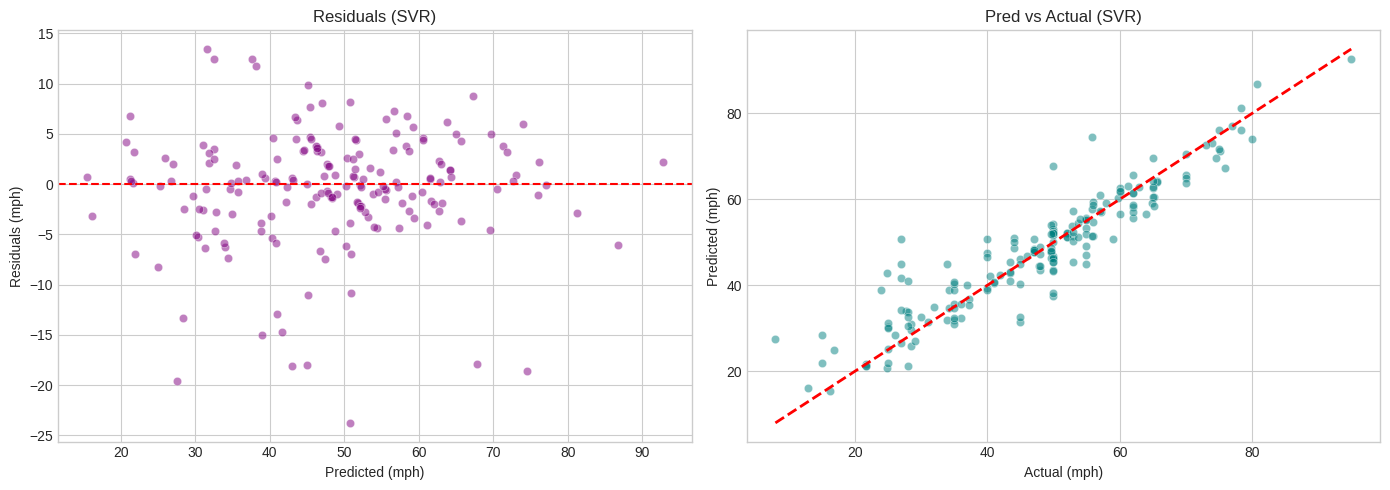

In [7]:
top2 = summary_reg["Model"].head(2).tolist()

grids = {
    "Linear Regression": {},
    "Ridge Regression": {"reg__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    "Lasso Regression": {"reg__alpha": [0.001, 0.01, 0.1, 1.0, 10.0]},
    "ElasticNet Regression": {
        "reg__alpha": [0.01, 0.1, 1.0, 10.0],
        "reg__l1_ratio": [0.2, 0.5, 0.7, 0.9],
    },
    "Polynomial Regression": {
        "prep__num__poly__degree": [2, 3],
        "prep__num__poly__interaction_only": [True, False],
    },
    "SVR": {
        "reg__C": [0.1, 1.0, 10.0, 100.0],
        "reg__gamma": ["scale", "auto"],
        "reg__epsilon": [0.01, 0.1, 0.2],
    },
    "KNN": {
        "reg__n_neighbors": [3, 5, 7, 9, 11],
        "reg__weights": ["uniform", "distance"],
        "reg__metric": ["minkowski", "manhattan"],
    },
    "Random Forest": {
        "reg__n_estimators": [100, 200],
        "reg__max_depth": [6, 10, 14, None],
    },
    "Gradient Boosting": {
        "reg__n_estimators": [100, 200],
        "reg__learning_rate": [0.03, 0.1, 0.2],
        "reg__max_depth": [3, 5, 7],
    },
    "Decision Tree": {
        "reg__max_depth": [4, 6, 8, 12, None],
        "reg__min_samples_leaf": [1, 3, 5],
    },
}

tuned_fits = {}
scores = {}

for name in top2:
    p = models_reg[name]
    grid = grids[name]
    if grid:
        gs = GridSearchCV(p, grid, cv=5, scoring="r2", n_jobs=-1)
        gs.fit(X_train_reg, y_train_reg)
        best_est = gs.best_estimator_
    else:
        p.fit(X_train_reg, y_train_reg)
        best_est = p
    tuned_fits[name] = best_est
    scores[name] = r2_score(y_test_reg, best_est.predict(X_test_reg))

best_name = max(scores, key=scores.get)
best_p = tuned_fits[best_name]
best_preds = best_p.predict(X_test_reg)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(
    x=best_preds,
    y=y_test_reg - best_preds,
    alpha=0.5,
    ax=ax[0],
    color="purple",
)
ax[0].axhline(y=0, color="red", linestyle="--")
ax[0].set(
    title=f"Residuals ({best_name})",
    xlabel="Predicted (mph)",
    ylabel="Residuals (mph)",
)
sns.scatterplot(
    x=y_test_reg, y=best_preds, alpha=0.5, ax=ax[1], color="teal"
)
ax[1].plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()],
    "r--",
    lw=2,
)
ax[1].set(
    title=f"Pred vs Actual ({best_name})",
    xlabel="Actual (mph)",
    ylabel="Predicted (mph)",
)
plt.tight_layout()
plt.savefig("residuals.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
if best_name in ["Random Forest", "Gradient Boosting", "Decision Tree"]:
    ohe_cols = list(
        best_p.named_steps["prep"]
        .named_transformers_["cat"]
        .named_steps["ohe"]
        .get_feature_names_out(cat_cols)
    )
    all_cols = num_cols + ohe_cols
    imp = pd.DataFrame({
        "Feature": all_cols,
        "Importance": best_p.named_steps["reg"].feature_importances_,
    })
    imp = imp.sort_values(by="Importance", ascending=False).head(10)
    plt.figure(figsize=(9, 5))
    sns.barplot(x="Importance", y="Feature", data=imp, palette="viridis")
    plt.title(f"Feature Importance ({best_name})")
    plt.tight_layout()
    plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()
elif best_name in [
    "Linear Regression",
    "Ridge Regression",
    "Lasso Regression",
    "ElasticNet Regression",
]:
    ohe_cols = list(
        best_p.named_steps["prep"]
        .named_transformers_["cat"]
        .named_steps["ohe"]
        .get_feature_names_out(cat_cols)
    )
    all_cols = num_cols + ohe_cols
    coefs = pd.DataFrame(
        {"Feature": all_cols, "Coefficient": best_p.named_steps["reg"].coef_}
    )
    coefs["Abs_Coef"] = coefs["Coefficient"].abs()
    coefs = coefs.sort_values(by="Abs_Coef", ascending=False).head(10)
    plt.figure(figsize=(9, 5))
    sns.barplot(x="Coefficient", y="Feature", data=coefs, palette="coolwarm")
    plt.title(f"Top Model Coefficients ({best_name})")
    plt.tight_layout()
    plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()

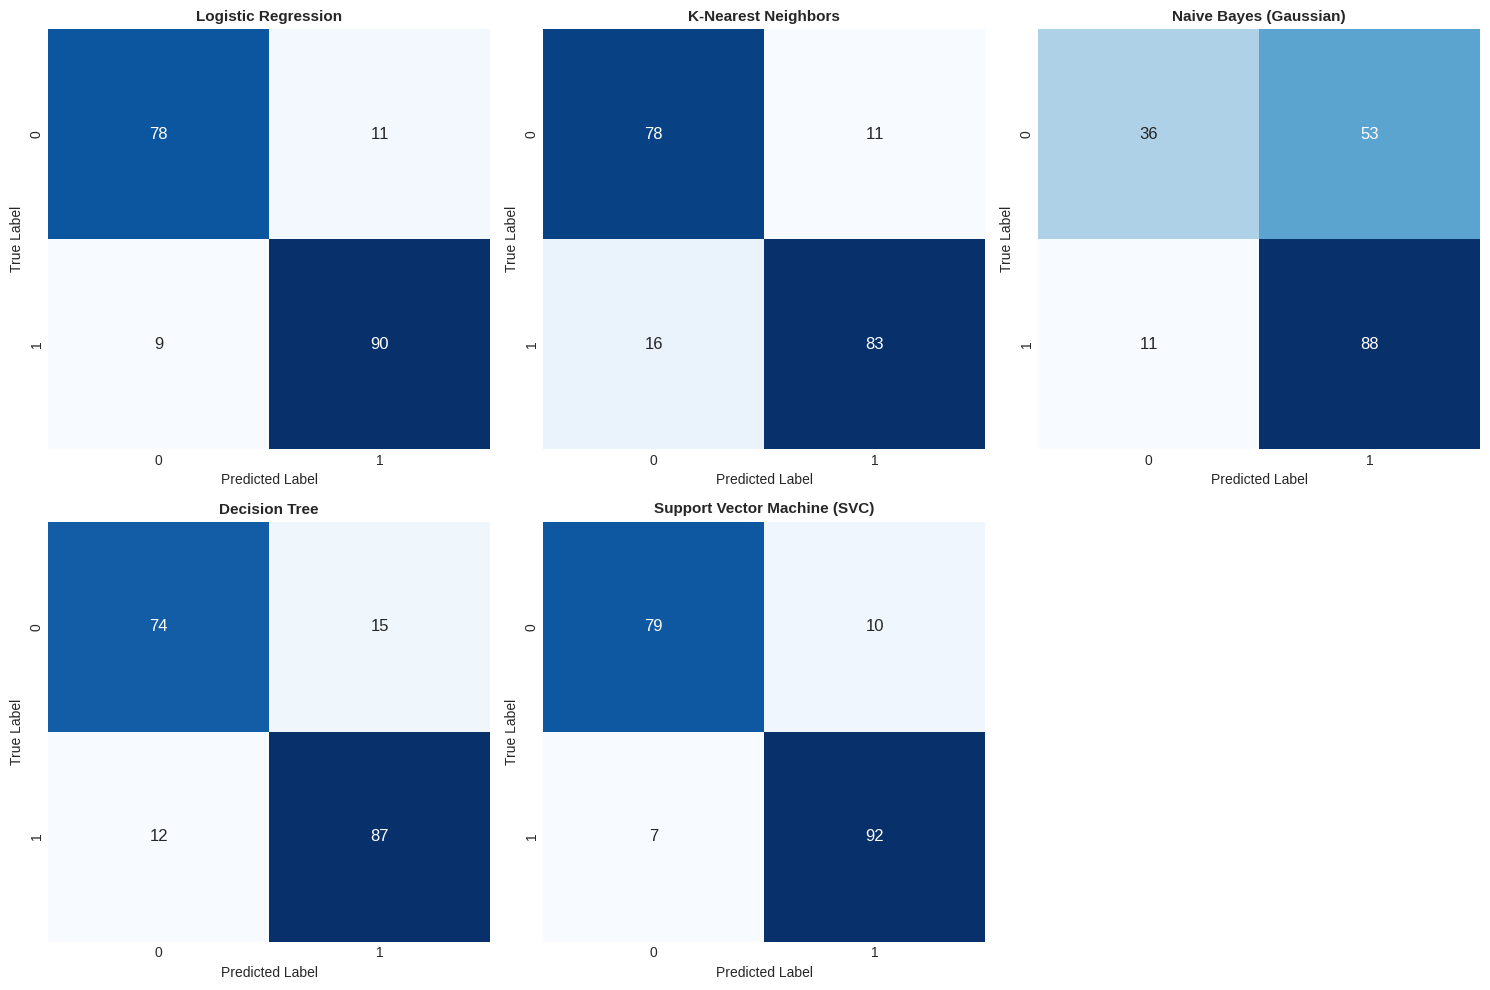

--- REVIEW 1: CLASSIFICATION PART A RESULTS ---
                       Model  Accuracy  Precision  Recall  Weighted F1
Support Vector Machine (SVC)    0.9096     0.9098  0.9096       0.9095
         Logistic Regression    0.8936     0.8937  0.8936       0.8935
         K-Nearest Neighbors    0.8564     0.8578  0.8564       0.8565
               Decision Tree    0.8564     0.8565  0.8564       0.8562
      Naive Bayes (Gaussian)    0.6596     0.6913  0.6596       0.6368


In [9]:
median_speed = df["speed_mph_clean"].median()
df["is_fast_coaster"] = (df["speed_mph_clean"] >= median_speed).astype(int)
target_cls = "is_fast_coaster"

df_cls = df.dropna(subset=[target_cls]).copy()
for c in num_cols:
    if df_cls[c].isna().all():
        df_cls[c] = 0.0

X_cls = df_cls[num_cols + cat_cols]
y_cls = df_cls[target_cls]

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=SEED, stratify=y_cls
)

models_cls = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=SEED
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Naive Bayes (Gaussian)": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=SEED),
    "Support Vector Machine (SVC)": SVC(
        C=1.0, kernel="rbf", probability=True, random_state=SEED
    ),
}

res_cls = []
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, (name, clf) in enumerate(models_cls.items()):
    p = Pipeline([("prep", prep), ("clf", clf)])
    p.fit(X_train_cls, y_train_cls)
    preds = p.predict(X_test_cls)
    acc = accuracy_score(y_test_cls, preds)
    prec = precision_score(
        y_test_cls, preds, average="weighted", zero_division=0
    )
    rec = recall_score(y_test_cls, preds, average="weighted", zero_division=0)
    f1 = f1_score(y_test_cls, preds, average="weighted", zero_division=0)
    res_cls.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "Weighted F1": round(f1, 4),
    })
    cm = confusion_matrix(y_test_cls, preds)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[idx],
        cbar=False,
        annot_kws={"size": 12},
    )
    axes[idx].set_title(f"{name}", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")

fig.delaxes(axes[5])
plt.tight_layout()
plt.savefig("part_a_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

summary_cls = (
    pd.DataFrame(res_cls)
    .sort_values(by="Weighted F1", ascending=False)
    .reset_index(drop=True)
)
print("--- REVIEW 1: CLASSIFICATION PART A RESULTS ---")
print(summary_cls.to_string(index=False))